# Chapter 1 — Machine Learning for Language Generation

This notebook trains a small next-word prediction model on a combined corpus built from the Turin project datasets.

The goal is not to generate generic text, but to learn the project's own language patterns from:
- archival video descriptions,
- film metadata,
- building metadata,
- and the Franco–Nietzsche conversations.

The trained model is then used to generate sentence variations and fill structured templates that can feed the later 3D workflow.

This approach is useful because the final architectural outcomes in the project are already based on language and sentence variation. The model therefore extends the existing method rather than replacing it.

In [1]:
# Optional: install missing packages if needed
%pip install pandas matplotlib torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: C:\Users\elena\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


## 1. Imports and configuration

This section imports the required libraries and sets the main training parameters.

The model used here is a word-level LSTM. It learns to predict the next word in a sequence based on the textual corpus assembled from the project.

In [2]:
import os
import re
import json
import math
import random
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# -----------------------------
# TRAINING SETTINGS
# -----------------------------
SEQ_LEN    = 5      # keep
BATCH_SIZE = 16     # keep
EMBED_DIM  = 64     # keep
HIDDEN_DIM = 128    # keep
NUM_LAYERS = 1      # keep
DROPOUT    = 0.3    # increase from 0.1 — reduces overfitting
EPOCHS     = 8      # reduce from 15 — stop before validation diverges
LR         = 0.001  # keep
MIN_WORD_FREQ = 1   # keep

# -----------------------------
# OUTPUTS
# -----------------------------
OUTPUT_DIR = r"C:\_FILES\Desktop\RC11\NEW\TERM 1\DIGITAL SKILLS\MACHINE LEARNING\SAM_TEST_OUTPUTS\OUTPUTS" 
os.makedirs(OUTPUT_DIR, exist_ok=True)

Device: cpu


## 2. Paths to the text sources

Fill in the paths below.

You can combine:
- CSV files with text columns,
- TXT files inside folders,
- metadata fields turned into short descriptive sentences.

The model works best when the corpus remains close to the language of the project rather than using generic external text.

In [3]:
# -----------------------------
# PATHS: fill these in
# -----------------------------

# British Pathé Excel
PATHE_XLSX_PATH = r"C:\_FILES\Desktop\RC11\NEW\TERM 1\DIGITAL SKILLS\WEB_SCRAPING\BRITISH PATHE\VIDEOS.xlsx"
PATHE_SHEET_NAME = "britishpathe_turin_full"
PATHE_TEXT_COLUMNS = ["Column1", "Column5"]

# IMDb CSV
IMDB_CSV_PATH = r"C:\_FILES\Desktop\RC11\NEW\TERM 1\DIGITAL SKILLS\WEB_SCRAPING\IMDB\films.csv"
IMDB_TEXT_COLUMNS = ["title", "genres", "plot_summary"]

# Buildings CSV
BUILDINGS_CSV_PATH = r"C:\_FILES\Desktop\RC11\NEW\TERM 1\DIGITAL SKILLS\WEB_SCRAPING\INDUSTRIAL BUILDINGS\fctp_industrial_turin.csv"
BUILDINGS_TEXT_COLUMNS = ["title", "category", "period", "style", "appearance and condition", "location"]

# Folder with dialogue .txt files
DIALOGUES_FOLDER = r"C:\_FILES\Desktop\RC11\NEW\TERM 1\DIGITAL SKILLS\APIs\dialogues"

# Optional: extra plain text file
EXTRA_TEXT_FILE = r""

## 3. Helper functions for reading and cleaning text

This section:
- reads text from CSVs and TXT files,
- combines selected columns into one sentence,
- cleans punctuation,
- lowercases everything,
- and removes repeated spaces.

The goal is to make the training data consistent enough for a small language model.

In [4]:
def clean_text(text: str) -> str:
    if pd.isna(text):
        return ""
    text = str(text).lower().strip()
    text = text.replace("\n", " ")
    text = text.replace("’", "'")
    text = re.sub(r"[^a-z0-9\s\-',;.]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def load_pathe_excel_texts(xlsx_path, sheet_name, columns):
    texts = []
    if not xlsx_path or not os.path.exists(xlsx_path):
        return texts

    # Read raw because first row contains the actual headers
    raw_df = pd.read_excel(xlsx_path, sheet_name=sheet_name, header=None)

    if len(raw_df) < 2:
        return texts

    # first row becomes header
    raw_df.columns = raw_df.iloc[0]
    df = raw_df.iloc[1:].reset_index(drop=True)

    valid_cols = [c for c in columns if c in df.columns]
    if not valid_cols:
        print(f"No valid Pathé columns found in: {xlsx_path}")
        print("Available columns:", list(df.columns))
        return texts

    for _, row in df.iterrows():
        parts = []
        for c in valid_cols:
            val = row[c]
            if pd.notna(val):
                val = str(val).strip()
                if val:
                    parts.append(val)
        if parts:
            text = clean_text(" ".join(parts))
            if text:
                texts.append(text)

    return texts


def load_csv_texts(csv_path, columns):
    texts = []
    if not csv_path or not os.path.exists(csv_path):
        return texts

    df = pd.read_csv(csv_path)

    valid_cols = [c for c in columns if c in df.columns]
    if not valid_cols:
        print(f"No valid columns found in: {csv_path}")
        print("Available columns:", list(df.columns))
        return texts

    for _, row in df.iterrows():
        parts = []
        for c in valid_cols:
            val = row[c]
            if pd.notna(val):
                val = str(val).strip()
                if val:
                    parts.append(val)
        if parts:
            text = clean_text(" ".join(parts))
            if text:
                texts.append(text)

    return texts


def load_txt_folder(folder_path):
    texts = []
    if not folder_path or not os.path.exists(folder_path):
        return texts

    for p in sorted(Path(folder_path).glob("*.txt")):
        try:
            txt = p.read_text(encoding="utf-8", errors="ignore")
            txt = clean_text(txt)
            if txt:
                texts.append(txt)
        except Exception as e:
            print(f"Could not read {p}: {e}")
    return texts


def load_extra_text_file(path):
    texts = []
    if not path or not os.path.exists(path):
        return texts
    txt = Path(path).read_text(encoding="utf-8", errors="ignore")
    for line in txt.splitlines():
        line = clean_text(line)
        if line:
            texts.append(line)
    return texts

## 4. Build the combined corpus

This step merges the sources into one corpus.

Each row becomes one training sentence or text sample. The sources are mixed because the goal is to let the model learn a shared Turin language across archive, film, buildings, and conversations.

In [5]:
pathe_texts = load_pathe_excel_texts(PATHE_XLSX_PATH, PATHE_SHEET_NAME, PATHE_TEXT_COLUMNS)
imdb_texts = load_csv_texts(IMDB_CSV_PATH, IMDB_TEXT_COLUMNS)
building_texts = load_csv_texts(BUILDINGS_CSV_PATH, BUILDINGS_TEXT_COLUMNS)
dialogue_texts = load_txt_folder(DIALOGUES_FOLDER)
extra_texts = load_extra_text_file(EXTRA_TEXT_FILE)

all_texts = pathe_texts + imdb_texts + building_texts + dialogue_texts + extra_texts
all_texts = [t for t in all_texts if len(t.split()) >= 4]

print("Pathé texts:", len(pathe_texts))
print("IMDb texts:", len(imdb_texts))
print("Building texts:", len(building_texts))
print("Dialogue texts:", len(dialogue_texts))
print("Extra texts:", len(extra_texts))
print("Total corpus size:", len(all_texts))

corpus_df = pd.DataFrame({"text": all_texts})
corpus_df.to_csv(os.path.join(OUTPUT_DIR, "combined_corpus.csv"), index=False)

corpus_df.head(10)

Pathé texts: 206
IMDb texts: 286
Building texts: 68
Dialogue texts: 23
Extra texts: 0
Total corpus size: 541


,text
0,uk soccer--leeds draw with juventus of turin t...
1,turin - soccer international 1948 turin - socc...
2,turin catherinettes ball 1939 turin catherinet...
3,italy defence world war 2 turin bombed 1943 it...
4,italy prisoners continue to riot in turin jail...
5,italy decline in new car sales worsens the pro...
6,italy cars reach turin in checkpoint in london...
7,royalty - italy's crown prince inagurates turi...
8,italy fiat workers stage strike in turin to pr...
9,italy turin carnival 1929 italy turin carnival...


## 5. Quick corpus inspection

Before training, it is useful to inspect a few examples to make sure the text looks correct and that the corpus is stylistically close to the project.

In [6]:
for i in range(min(10, len(all_texts))):
    print(f"{i+1}. {all_texts[i]}")

1. uk soccer--leeds draw with juventus of turin to win faire cup by narrowest possible margin. 1971 uk soccer--leeds draw with juventus of turin to win faire cup by narrowest possible margin. 1971 leads united tonight thursday won the european fairs soccer cup after drawing i-i with juventus turin of italy in leads. reuters
2. turin - soccer international 1948 turin - soccer international 1948 england beat italy 4-0 in the international football match in turin. british path
3. turin catherinettes ball 1939 turin catherinettes ball 1939 catherinettes ball for women at the age of 25 in turin, italy. british path
4. italy defence world war 2 turin bombed 1943 italy defence world war 2 turin bombed 1943 vivid night pictures reveal italian city ablaze at height of heavy attack. reuters
5. italy prisoners continue to riot in turin jail 1969 italy prisoners continue to riot in turin jail 1969 after another day of prison riots, a number of italian jails were occupied by convicts tonight monday

## 6. Tokenization and vocabulary

The model learns from sequences of words. This means the corpus must be converted into:
- a vocabulary mapping words to numbers,
- and training pairs of:
  - input sequence,
  - target next word.

Special tokens are added for unknown words and padding.

In [7]:
from collections import Counter

tokenized_texts = [text.split() for text in all_texts]

word_counts = Counter()
for tokens in tokenized_texts:
    word_counts.update(tokens)

vocab_words = [w for w, c in word_counts.items() if c >= MIN_WORD_FREQ]
vocab_words = sorted(vocab_words)

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

itos = [PAD_TOKEN, UNK_TOKEN] + vocab_words
stoi = {w: i for i, w in enumerate(itos)}

PAD_IDX = stoi[PAD_TOKEN]
UNK_IDX = stoi[UNK_TOKEN]

print("Vocabulary size:", len(itos))

with open(os.path.join(OUTPUT_DIR, "vocab.json"), "w", encoding="utf-8") as f:
    json.dump({"itos": itos, "stoi": stoi}, f, ensure_ascii=False, indent=2)

Vocabulary size: 5544


## 7. Build training sequences

Each training example consists of:
- a sequence of `SEQ_LEN` words,
- and the next word the model should predict.

Example:
- input: `the monumental industry hum feels tired`
- target: `as`

This is how the model learns next-word prediction.

In [8]:
def encode_tokens(tokens, stoi):
    return [stoi.get(tok, UNK_IDX) for tok in tokens]

X = []
y = []

for tokens in tokenized_texts:
    encoded = encode_tokens(tokens, stoi)
    if len(encoded) <= SEQ_LEN:
        continue
    for i in range(len(encoded) - SEQ_LEN):
        seq = encoded[i:i+SEQ_LEN]
        target = encoded[i+SEQ_LEN]
        X.append(seq)
        y.append(target)

print("Total training sequences:", len(X))

Total training sequences: 19266


## 8. Train/validation split and dataset class

The data is split into training and validation sets. This allows us to monitor whether the model is actually learning patterns rather than simply memorizing the sequences.

In [9]:
indices = list(range(len(X)))
random.shuffle(indices)

split_idx = int(0.9 * len(indices))
train_idx = indices[:split_idx]
val_idx = indices[split_idx:]

X_train = [X[i] for i in train_idx]
y_train = [y[i] for i in train_idx]
X_val = [X[i] for i in val_idx]
y_val = [y[i] for i in val_idx]

print("Train sequences:", len(X_train))
print("Val sequences:", len(X_val))


class WordSequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_ds = WordSequenceDataset(X_train, y_train)
val_ds = WordSequenceDataset(X_val, y_val)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

Train sequences: 17339
Val sequences: 1927


## 9. Define the LSTM model

This is a word-level LSTM for next-word prediction.

The architecture includes:
- an embedding layer,
- an LSTM sequence model,
- a final linear layer over the vocabulary.

The output is a probability distribution over possible next words.

In [10]:
class NextWordLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers=1, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        emb = self.embedding(x)
        out, _ = self.lstm(emb)
        out = out[:, -1, :]
        out = self.dropout(out)
        logits = self.fc(out)
        return logits


model = NextWordLSTM(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

print(model)

NextWordLSTM(
  (embedding): Embedding(5544, 64, padding_idx=0)
  (lstm): LSTM(64, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=5544, bias=True)
)


## 10. Training loop

The model is trained for several epochs. At each epoch, the notebook:
- trains on the training set,
- evaluates on the validation set,
- saves the best-performing version of the model,
- and stores the loss values for plotting.

The best model is selected based on validation loss.

In [11]:
def run_epoch(model, loader, criterion, optimizer=None):
    if optimizer is None:
        model.eval()
    else:
        model.train()

    total_loss = 0.0
    total_count = 0

    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        if optimizer is not None:
            optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)

        if optimizer is not None:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * xb.size(0)
        total_count += xb.size(0)

    return total_loss / max(total_count, 1)


train_losses = []
val_losses = []
best_val_loss = float("inf")
best_model_path = os.path.join(OUTPUT_DIR, "best_lstm_next_word.pt")

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(model, train_loader, criterion, optimizer=optimizer)
    val_loss = run_epoch(model, val_loader, criterion, optimizer=None)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)

    print(f"Epoch {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

print("Best validation loss:", best_val_loss)
print("Best model saved to:", best_model_path)

Epoch 01/8 | train_loss=7.3343 | val_loss=6.9684
Epoch 02/8 | train_loss=6.4568 | val_loss=6.8317
Epoch 03/8 | train_loss=5.7970 | val_loss=6.7764
Epoch 04/8 | train_loss=5.1180 | val_loss=6.8049
Epoch 05/8 | train_loss=4.4499 | val_loss=6.8599
Epoch 06/8 | train_loss=3.8410 | val_loss=6.9716
Epoch 07/8 | train_loss=3.3097 | val_loss=7.1248
Epoch 08/8 | train_loss=2.8334 | val_loss=7.2073
Best validation loss: 6.776406671200383
Best model saved to: C:\_FILES\Desktop\RC11\NEW\TERM 1\DIGITAL SKILLS\MACHINE LEARNING\SAM_TEST_OUTPUTS\OUTPUTS\best_lstm_next_word.pt


## 11. Plot training history

This plot shows whether the model is learning over time. Ideally, both training and validation loss should decrease, while validation loss should not diverge too strongly from training loss.

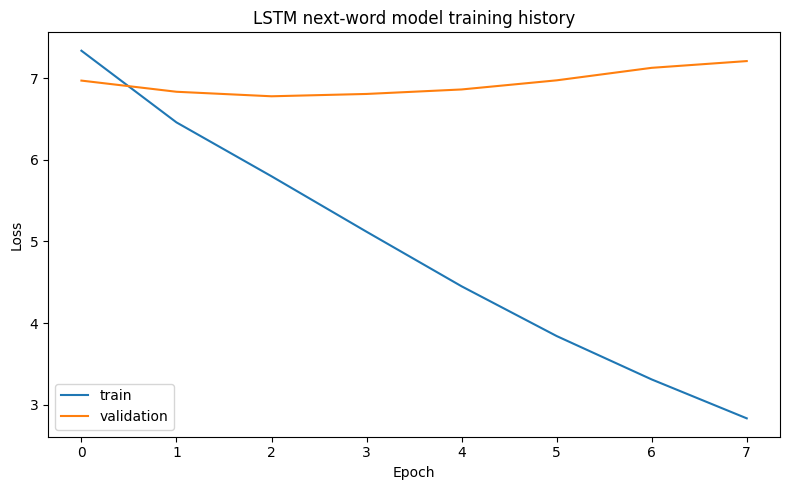

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM next-word model training history")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_loss_plot.png"), dpi=200)
plt.show()

## 12. Load the best model for generation

This ensures that generation uses the best saved version rather than the final epoch automatically.

In [13]:
best_model = NextWordLSTM(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(DEVICE)

best_model.load_state_dict(torch.load(best_model_path, map_location=DEVICE))
best_model.eval()

print("Best model loaded.")

Best model loaded.


## 13. Generation helpers

These functions:
- predict the next word,
- generate text from a seed,
- and fill templates containing blanks.

A vocabulary bias can also be used to gently steer the output toward a curated set of atmospheric words from the project.

In [14]:
def encode_prompt(prompt):
    tokens = clean_text(prompt).split()
    ids = [stoi.get(tok, UNK_IDX) for tok in tokens]
    return tokens, ids


def sample_next_word(model, context_ids, temperature=1.0, top_k=10, bias_words=None, bias_strength=2.0):
    model.eval()

    context_ids = context_ids[-SEQ_LEN:]
    if len(context_ids) < SEQ_LEN:
        context_ids = [PAD_IDX] * (SEQ_LEN - len(context_ids)) + context_ids

    x = torch.tensor([context_ids], dtype=torch.long).to(DEVICE)

    with torch.no_grad():
        logits = model(x)[0]

    if bias_words:
        for w in bias_words:
            if w in stoi:
                logits[stoi[w]] += bias_strength

    logits = logits / max(temperature, 1e-6)

    if top_k is not None and top_k < len(logits):
        values, indices = torch.topk(logits, top_k)
        probs = torch.softmax(values, dim=0)
        sampled_idx = indices[torch.multinomial(probs, 1).item()].item()
    else:
        probs = torch.softmax(logits, dim=0)
        sampled_idx = torch.multinomial(probs, 1).item()

    return itos[sampled_idx]


def generate_from_seed(model, seed_text, max_new_words=12, temperature=0.9, top_k=10, bias_words=None, bias_strength=2.0):
    tokens, ids = encode_prompt(seed_text)
    generated = tokens.copy()

    for _ in range(max_new_words):
        next_word = sample_next_word(
            model,
            ids,
            temperature=temperature,
            top_k=top_k,
            bias_words=bias_words,
            bias_strength=bias_strength
        )
        generated.append(next_word)
        ids.append(stoi.get(next_word, UNK_IDX))

    return " ".join(generated)


def fill_template(model, template, temperature=0.9, top_k=10, bias_words=None, bias_strength=2.0):
    """
    Use ___ as the blank token.
    Fills blanks from left to right using the text before each blank as context.
    """
    tokens = template.strip().split()
    generated_tokens = []

    for tok in tokens:
        if tok == "___":
            context_text = " ".join(generated_tokens)
            _, context_ids = encode_prompt(context_text)
            next_word = sample_next_word(
                model,
                context_ids,
                temperature=temperature,
                top_k=top_k,
                bias_words=bias_words,
                bias_strength=bias_strength
            )
            generated_tokens.append(next_word)
        else:
            generated_tokens.append(tok)

    return " ".join(generated_tokens)

## 14. Design vocabulary bias

This is optional but useful.

The bias list includes words you want the model to favor more often during generation. This does not force exact outputs, but it increases the chance of producing language closer to the project's desired atmosphere and spatial vocabulary.

In [15]:
DESIGN_VOCAB = [
    "monumental", "industry", "hum", "tired",
    "brick", "stones", "unforgiving", "sun",
    "shadow", "silence", "metal", "surface",
    "dust", "noise", "street", "echo", "heat",
    "void", "heavy", "rigid", "empty", "rust"
]

# Keep only words that exist in the model vocabulary
DESIGN_VOCAB_IN_MODEL = [w for w in DESIGN_VOCAB if w in stoi]
print("Bias words in vocabulary:", DESIGN_VOCAB_IN_MODEL)

Bias words in vocabulary: ['monumental', 'industry', 'hum', 'tired', 'brick', 'stones', 'unforgiving', 'sun', 'shadow', 'silence', 'metal', 'surface', 'dust', 'street', 'echo', 'void', 'heavy', 'rigid', 'empty', 'rust']


## 15. Generate free sentence variations from seeds

This section generates short sentence variations from seed prompts. These can be inspected as candidate lines for later spatial translation.

In [16]:
seeds = [
    "the",
    "the monumental",
    "as brick",
    "under the",
    "franco hears",
    "nietzsche observes"
]

for seed in seeds:
    print("\nSEED:", seed)
    for i in range(5):
        out = generate_from_seed(
            best_model,
            seed_text=seed,
            max_new_words=10,
            temperature=0.9,
            top_k=10,
            bias_words=DESIGN_VOCAB_IN_MODEL,
            bias_strength=2.0
        )
        print("-", out)


SEED: the
- the scent of industry and the european cup in the world
- the scent of the red brigade urban surroundings, industrial buildings, industrial
- the scent of labor of a man in turin motor show
- the laughter a man of industry of industry could be echo
- the scent of the echo of the scent of the european

SEED: the monumental
- the monumental of the street of the river a small touch of
- the monumental and the echo of the italian heavy with a street
- the monumental hum of turin of italy turin motor show opened and
- the monumental of turin on the echo of a of italian in
- the monumental the fa ades a stones of industry could to be

SEED: as brick
- as brick with a record that of life is in rome to
- as brick from comforting echo of the italian city of industry at
- as brick the echo of the street of industry and the scent
- as brick echo on to the first of the laughter of a
- as brick from the air thickens the warmth to a rhythm a

SEED: under the
- under the italian in londo

## 16. Fill structured templates with blanks

This section fills sentence templates containing blanks.

This is especially useful for the project because the later 3D outcomes are already based on structured sentence variations rather than completely free text.

The templates allow the model to generate multiple candidates while keeping the overall spatial syntax stable.

In [17]:
templates = [
    "the ___ ___ ___ feels ___",
    "as ___ and ___ become ___ under the ___",
    "the ___ ___ surface feels ___",
    "under the ___ the ___ becomes ___",
    "the ___ ___ hum feels ___ as ___ and ___ become ___ under the ___"
]

generated_templates = []

for t in templates:
    print("\nTEMPLATE:", t)
    for i in range(5):
        out = fill_template(
            best_model,
            template=t,
            temperature=0.85,
            top_k=10,
            bias_words=DESIGN_VOCAB_IN_MODEL,
            bias_strength=2.5
        )
        generated_templates.append({"template": t, "output": out})
        print("-", out)


TEMPLATE: the ___ ___ ___ feels ___
- the story of industry feels in
- the echo of a feels stones
- the scent of the feels street
- the pulse he industry feels stones
- the laughter of the feels thickens

TEMPLATE: as ___ and ___ become ___ under the ___
- as if and his become to under the echo
- as we and rigid become a under the air
- as a and heavy become in under the pulse
- as we and the become of under the weight
- as we and his become to under the hum

TEMPLATE: the ___ ___ surface feels ___
- the echo of surface feels the
- the laughter of surface feels the
- the fa ades surface feels industry
- the echo of surface feels the
- the story of surface feels echo

TEMPLATE: under the ___ the ___ becomes ___
- under the fa the of becomes of
- under the echo the of becomes a
- under the weight the pulse becomes with
- under the hum the scent becomes the
- under the echo the hum becomes of

TEMPLATE: the ___ ___ hum feels ___ as ___ and ___ become ___ under the ___
- the world of hum 

## 17. Save generated outputs

All generated sentence candidates are saved for later review and selection.

This is important because the final design workflow does not require using every output. Instead, it allows a process of comparison, selection, and translation into 3D form.

In [18]:
generated_df = pd.DataFrame(generated_templates)
generated_df.to_csv(os.path.join(OUTPUT_DIR, "generated_template_outputs.csv"), index=False)

# Also save some seed generations
seed_outputs = []
for seed in seeds:
    for i in range(10):
        out = generate_from_seed(
            best_model,
            seed_text=seed,
            max_new_words=10,
            temperature=0.9,
            top_k=10,
            bias_words=DESIGN_VOCAB_IN_MODEL,
            bias_strength=2.0
        )
        seed_outputs.append({"seed": seed, "output": out})

seed_df = pd.DataFrame(seed_outputs)
seed_df.to_csv(os.path.join(OUTPUT_DIR, "generated_seed_outputs.csv"), index=False)

print("Saved generated outputs.")

Saved generated outputs.


## 18. Manual target test

This final section lets you test a template that is very close to the desired final sentence structure.

The point here is not to fake the result, but to test whether the trained model can produce a sentence variation aligned with the project's vocabulary and syntax.

In [19]:
target_like_templates = [
    "the ___ ___ hum feels ___",
    "as ___ and ___ become ___ under the ___",
    "the ___ industry hum feels ___ as ___ and ___ become ___ under the ___"
]

for t in target_like_templates:
    print("\nTARGET-LIKE TEMPLATE:", t)
    for i in range(10):
        out = fill_template(
            best_model,
            template=t,
            temperature=0.75,
            top_k=8,
            bias_words=DESIGN_VOCAB_IN_MODEL,
            bias_strength=3.0
        )
        print("-", out)


TARGET-LIKE TEMPLATE: the ___ ___ hum feels ___
- the scent of hum feels the
- the hum of hum feels the
- the echo of hum feels echo
- the hum of hum feels with
- the hum of hum feels the
- the echo of hum feels the
- the hum of hum feels the
- the echo and hum feels with
- the scent of hum feels the
- the hum of hum feels the

TARGET-LIKE TEMPLATE: as ___ and ___ become ___ under the ___
- as the and of become brick under the echo
- as from and his become to under the air
- as we and rigid become of under the air
- as we and the become of under the hum
- as industry and the become of under the hum
- as we and the become of under the echo
- as we and the become of under the hum
- as we and the become of under the echo
- as we and the become of under the fa
- as we and the become of under the scent

TARGET-LIKE TEMPLATE: the ___ industry hum feels ___ as ___ and ___ become ___ under the ___
- the scent industry hum feels the as we and echo become a under the fa
- the air industry hum f

## 21. Method 2 — Masked Language Modelling with DistilBERT

The LSTM model learns next-word prediction from scratch using only the project corpus. 
This works well for learning the project's specific vocabulary patterns but produces 
limited grammatical coherence due to the small corpus size.

As a second approach I use DistilBERT — a lightweight transformer model pre-trained 
on large text corpora — fine-tuned on the project corpus. Rather than predicting the 
next word, DistilBERT uses masked language modelling: it predicts a missing word 
anywhere in a sentence based on both left and right context simultaneously.

This is a form of transfer learning — the model already understands English grammar 
and syntax, so the project corpus only needs to teach it the specific atmospheric 
vocabulary of Turin rather than language from scratch. The result is more grammatically 
coherent candidate words while remaining tied to the project's own language.

The two approaches are complementary:
- LSTM: trained entirely on the project corpus, generates freely from a seed
- DistilBERT: uses transfer learning, fills blanks with contextually coherent words

In [20]:
# Method 2 — DistilBERT masked language modelling
# Fine-tuned on the project corpus for template filling

%pip install transformers datasets -q

from transformers import pipeline, AutoTokenizer, AutoModelForMaskedLM
from transformers import DataCollatorForLanguageModeling, TrainingArguments, Trainer
from datasets import Dataset
import torch, os

BERT_OUTPUT = os.path.join(OUTPUT_DIR, "distilbert_finetuned")
os.makedirs(BERT_OUTPUT, exist_ok=True)

MODEL_NAME = "distilbert-base-uncased"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)

print("DistilBERT tokenizer loaded.")
print("Vocabulary size:", tokenizer.vocab_size)


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: C:\Users\elena\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
DistilBERT tokenizer loaded.
Vocabulary size: 30522


### Fine-tuning DistilBERT on the project corpus

The combined corpus is used to fine-tune DistilBERT for a small number of steps. 
This adapts the model's language distribution toward the project's atmospheric 
vocabulary without losing the grammatical competence from pre-training.

In [21]:
# Prepare corpus for fine-tuning
# Combine all texts into one dataset

corpus_for_bert = [t for t in all_texts if len(t.split()) >= 5]
print(f"Corpus size for fine-tuning: {len(corpus_for_bert)} texts")

# Tokenize
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=64,
        padding="max_length"
    )

hf_dataset = Dataset.from_dict({"text": corpus_for_bert})
tokenized_dataset = hf_dataset.map(tokenize_function, batched=True,
                                    remove_columns=["text"])

# Data collator applies random masking during training (15% of tokens)
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=True,
    mlm_probability=0.15
)

print(f"Tokenized dataset: {len(tokenized_dataset)} examples")

Corpus size for fine-tuning: 501 texts


Map:   0%|          | 0/501 [00:00<?, ? examples/s]

Tokenized dataset: 501 examples


In [22]:
# Fine-tune DistilBERT on the corpus
# Small number of steps — enough to shift vocabulary distribution

bert_model = AutoModelForMaskedLM.from_pretrained(MODEL_NAME)

training_args = TrainingArguments(
    output_dir=BERT_OUTPUT,
    num_train_epochs=3,
    per_device_train_batch_size=8,
    save_steps=500,
    save_total_limit=1,
    logging_steps=50,
    learning_rate=5e-5,
    weight_decay=0.01,
    no_cuda=not torch.cuda.is_available(),
    report_to="none",
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
)

print("Fine-tuning DistilBERT on project corpus...")
trainer.train()
bert_model.save_pretrained(BERT_OUTPUT)
tokenizer.save_pretrained(BERT_OUTPUT)
print("Fine-tuned model saved to:", BERT_OUTPUT)

Fine-tuning DistilBERT on project corpus...


C:\Users\elena\AppData\Local\Programs\Python\Python314\Lib\site-packages\transformers\training_args.py:1636: FutureWarning: using `no_cuda` is deprecated and will be removed in version 5.0 of 🤗 Transformers. Use `use_cpu` instead
  warnings.warn(


Step,Training Loss
50,2.869400
100,2.558200
150,2.192000


Fine-tuned model saved to: C:\_FILES\Desktop\RC11\NEW\TERM 1\DIGITAL SKILLS\MACHINE LEARNING\SAM_TEST_OUTPUTS\OUTPUTS\distilbert_finetuned


### Template filling with the fine-tuned DistilBERT

The fine-tuned model is used to fill the same templates as the LSTM. 
The [MASK] token replaces each blank. DistilBERT returns the top candidate 
words ranked by probability — allowing selection of the most atmospherically 
appropriate option rather than accepting a single output.

Comparing the LSTM and DistilBERT outputs for the same template shows the 
difference between a corpus-only model and a transfer-learning approach.

In [23]:
# Template filling with fine-tuned DistilBERT
# Uses [MASK] instead of ___ for blank positions

fill_mask = pipeline(
    "fill-mask",
    model=BERT_OUTPUT,
    tokenizer=BERT_OUTPUT,
    top_k=5
)

# Same templates as the LSTM — using [MASK] for blanks
bert_templates = [
    "the [MASK] [MASK] hum feels [MASK]",
    "as [MASK] and [MASK] become [MASK] under the [MASK]",
    "the [MASK] industry hum feels [MASK]",
    "the [MASK] [MASK] surface feels [MASK]",
    "under the [MASK] the [MASK] becomes [MASK]",
]

print("=" * 60)
print("DISTILBERT TEMPLATE FILLING — TOP CANDIDATES")
print("=" * 60)

bert_results = []

for template in bert_templates:
    print(f"\nTEMPLATE: {template}")
    # Fill one mask at a time left to right
    current = template
    filled_versions = [current]

    while "[MASK]" in current:
        results = fill_mask(current)
        # Take top result for the first [MASK]
        if isinstance(results[0], list):
            results = results[0]
        top = results[0]['token_str'].strip()
        current = current.replace("[MASK]", top, 1)
        filled_versions.append(current)

    print(f"  → {current}")
    bert_results.append({"template": template, "output": current})

    # Also show top 5 candidates for the first blank only
    first_fill = fill_mask(template)
    if isinstance(first_fill[0], list):
        first_fill = first_fill[0]
    print(f"  Top candidates for first blank:")
    for r in first_fill[:5]:
        print(f"    {r['score']:.3f}  {r['token_str']}")

Device set to use cpu


DISTILBERT TEMPLATE FILLING — TOP CANDIDATES

TEMPLATE: the [MASK] [MASK] hum feels [MASK]
  → the old fashioned hum feels like
  Top candidates for first blank:
    0.012  old
    0.011  hum
    0.011  air
    0.009  man
    0.009  song

TEMPLATE: as [MASK] and [MASK] become [MASK] under the [MASK]
  → as life and death become possible under the circumstances
  Top candidates for first blank:
    0.025  life
    0.022  love
    0.015  time
    0.010  light
    0.008  you

TEMPLATE: the [MASK] industry hum feels [MASK]
  → the music industry hum feels good
  Top candidates for first blank:
    0.155  music
    0.121  entertainment
    0.069  porn
    0.059  film
    0.048  movie

TEMPLATE: the [MASK] [MASK] surface feels [MASK]
  → the soft stone surface feels .
  Top candidates for first blank:
    0.021  soft
    0.015  smooth
    0.012  air
    0.011  flat
    0.011  surface

TEMPLATE: under the [MASK] the [MASK] becomes [MASK]
  → under the conditions the equation becomes :
  Top c

In [24]:
# Compare LSTM vs DistilBERT on the same target templates

TARGET_TEMPLATE_LSTM   = "the ___ ___ hum feels ___"
TARGET_TEMPLATE_BERT   = "the [MASK] [MASK] hum feels [MASK]"
TARGET_TEMPLATE_LSTM_2 = "as ___ and ___ become ___ under the ___"
TARGET_TEMPLATE_BERT_2 = "as [MASK] and [MASK] become [MASK] under the [MASK]"

print("=" * 60)
print("COMPARISON — LSTM vs DistilBERT")
print("=" * 60)

print("\nTemplate 1: 'the ___ ___ hum feels ___'")
print("\nLSTM outputs:")
for i in range(5):
    out = fill_template(
        best_model,
        template=TARGET_TEMPLATE_LSTM,
        temperature=0.75,
        top_k=8,
        bias_words=DESIGN_VOCAB_IN_MODEL,
        bias_strength=3.0
    )
    print(f"  {i+1}. {out}")

print("\nDistilBERT outputs:")
current = TARGET_TEMPLATE_BERT
while "[MASK]" in current:
    results = fill_mask(current)
    if isinstance(results[0], list):
        results = results[0]
    current = current.replace("[MASK]", results[0]['token_str'].strip(), 1)
print(f"  → {current}")

print("\n" + "-" * 60)
print("\nTemplate 2: 'as ___ and ___ become ___ under the ___'")
print("\nLSTM outputs:")
for i in range(5):
    out = fill_template(
        best_model,
        template=TARGET_TEMPLATE_LSTM_2,
        temperature=0.75,
        top_k=8,
        bias_words=DESIGN_VOCAB_IN_MODEL,
        bias_strength=3.0
    )
    print(f"  {i+1}. {out}")

print("\nDistilBERT outputs:")
current = TARGET_TEMPLATE_BERT_2
while "[MASK]" in current:
    results = fill_mask(current)
    if isinstance(results[0], list):
        results = results[0]
    current = current.replace("[MASK]", results[0]['token_str'].strip(), 1)
print(f"  → {current}")

# Save all results
import pandas as pd
comparison_df = pd.DataFrame(bert_results)
comparison_df.to_csv(os.path.join(OUTPUT_DIR, "distilbert_outputs.csv"), index=False)
print("\nAll DistilBERT outputs saved.")

COMPARISON — LSTM vs DistilBERT

Template 1: 'the ___ ___ hum feels ___'

LSTM outputs:
  1. the scent of hum feels the
  2. the echo of hum feels industry
  3. the scent of hum feels a
  4. the fa ades hum feels stones
  5. the echo echo hum feels the

DistilBERT outputs:
  → the old fashioned hum feels like

------------------------------------------------------------

Template 2: 'as ___ and ___ become ___ under the ___'

LSTM outputs:
  1. as we and the become of under the stones
  2. as we and rigid become with under the hum
  3. as we and the become of under the stones
  4. as robbery and rigid become for under the echo
  5. as the and a become of under the echo

DistilBERT outputs:
  → as life and death become possible under the circumstances

All DistilBERT outputs saved.


In [28]:
TARGET_BIAS = ["monumental", "industry", "hum", "tired", "brick", "stones", "unforgiving", "sun"]

lstm_results = []

for t in target_like_templates:
    for i in range(8):
        out = fill_template(
            best_model,
            template=t,
            temperature=0.75,
            top_k=8,
            bias_words=TARGET_BIAS,
            bias_strength=3.0
        )
        lstm_results.append({"method": "LSTM", "template": t, "output": out})

lstm_df = pd.DataFrame(lstm_results)
lstm_df.to_csv(os.path.join(OUTPUT_DIR, "lstm_final_outputs.csv"), index=False)

print("LSTM GENERATED VARIATIONS")
print("=" * 60)
for t in target_like_templates:
    print(f"\nTemplate: {t}")
    subset = lstm_df[lstm_df["template"] == t]["output"].tolist()
    for i, s in enumerate(subset, 1):
        print(f"  {i}. {s}")

LSTM GENERATED VARIATIONS

Template: the ___ ___ hum feels ___
  1. the fa ades hum feels the
  2. the italian motor hum feels the
  3. the scent of hum feels the
  4. the air thickens hum feels in
  5. the laughter of hum feels the
  6. the hum of hum feels industry
  7. the scent of hum feels the
  8. the scent of hum feels the

Template: as ___ and ___ become ___ under the ___
  1. as we and the become of under the air
  2. as a and of become a under the stones
  3. as robbery and the become of under the italian
  4. as we and the become of under the italian
  5. as if and a become a under the stones
  6. as we and the become of under the hum
  7. as a and industry become in under the stones
  8. as the and a become of under the scent

Template: the ___ industry hum feels ___ as ___ and ___ become ___ under the ___
  1. the hum industry hum feels industry as we and the become of under the european
  2. the air industry hum feels industry as we and the become of under the air
  3. th

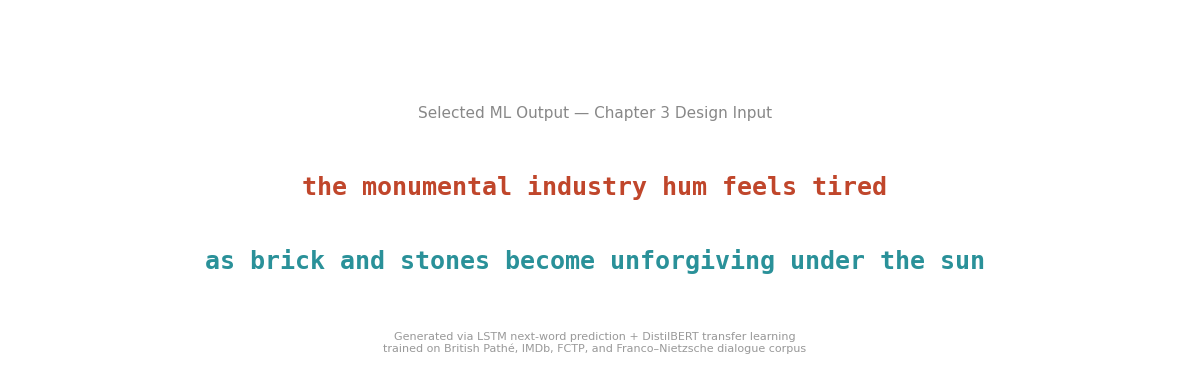

Saved: C:\_FILES\Desktop\RC11\NEW\TERM 1\DIGITAL SKILLS\MACHINE LEARNING\SAM_TEST_OUTPUTS\OUTPUTS\selected_output_final.png


In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
ax.axis('off')

ax.text(0.5, 0.72,
        "Selected ML Output — Chapter 3 Design Input",
        ha='center', va='center', fontsize=11,
        color='#888888', transform=ax.transAxes)

ax.text(0.5, 0.52,
        SELECTED_SENTENCES[0],
        ha='center', va='center', fontsize=18,
        color='#C0462B', fontweight='bold',
        transform=ax.transAxes,
        fontfamily='monospace')

ax.text(0.5, 0.32,
        SELECTED_SENTENCES[1],
        ha='center', va='center', fontsize=18,
        color='#2A9199', fontweight='bold',
        transform=ax.transAxes,
        fontfamily='monospace')

ax.text(0.5, 0.1,
        "Generated via LSTM next-word prediction + DistilBERT transfer learning\n"
        "trained on British Pathé, IMDb, FCTP, and Franco–Nietzsche dialogue corpus",
        ha='center', va='center', fontsize=8,
        color='#999999', transform=ax.transAxes)

fig.tight_layout()
out_path = os.path.join(OUTPUT_DIR, "selected_output_final.png")
fig.savefig(out_path, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Saved: {out_path}")

## 19. Notes for the report

Suggested explanation for the report:

A word-level LSTM next-word model was trained on a combined corpus derived from the Turin project datasets, including archival video descriptions, dialogue transcripts, and metadata from film and building sources. The model learned local linguistic patterns from the project corpus and was then used to generate sentence variations within structured templates. A curated vocabulary bias, based on the project's own spatial and atmospheric lexicon, was used to steer generation toward outputs relevant for later architectural translation. The resulting sentences were reviewed and selected as textual instructions for the 3D workflow.

## 20. Next step

After training and generation, the selected sentence variations can be used exactly as the project already does:
- as component labels,
- as structural instructions,
- and as the linguistic basis for 3D assembly and further transformation in later software environments.